# Did Leverkusen deserve to go unbeaten?

Every match of Leverkusen's 2023/24 league season replayed 10,000 times from the quality of its chances.

**Method.** Each shot is a goal with probability equal to its StatsBomb xG (penalties included). Adding up the
simulated goals for both teams gives a simulated score, and a result. Over 10,000 replays this gives:
- each match's **win / draw / defeat probabilities** and **expected points** (xPts);
- 10,000 **simulated seasons**, and so the chance of going a whole season unbeaten on these chances.

Seed 42, so the numbers are reproducible. Own goals aren't shots, so they aren't in the simulation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())
RAW = REPO / "data" / "raw" / "9_281"
FIGS = ROOT / "reports" / "figures"
LEV = "Bayer Leverkusen"
RED, GREY, DARK, MUTED, LIGHT, PINK = "#E32221", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#FCE9E9"
SRC = "Data: StatsBomb open data, Bundesliga 2023/24 (Leverkusen's 34 league matches). 10,000 simulations, seed 42"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})

def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)

E = pd.read_parquet(RAW / "events.parquet")
M = pd.read_parquet(RAW / "matches.parquet").sort_values("match_date").reset_index(drop=True)
S = E[E.type == "Shot"]
ABBR = {"Bayern Munich": "Bayern", "Borussia Dortmund": "Dortmund", "VfB Stuttgart": "Stuttgart", "RB Leipzig": "Leipzig",
        "Eintracht Frankfurt": "Frankfurt", "Borussia Mönchengladbach": "Gladbach", "FSV Mainz 05": "Mainz",
        "Werder Bremen": "Bremen", "Union Berlin": "Union", "FC Köln": "Köln", "Darmstadt 98": "Darmstadt",
        "Heidenheim": "Heidenheim", "VfL Bochum 1848": "Bochum", "Hoffenheim": "Hoffenheim", "Augsburg": "Augsburg",
        "Wolfsburg": "Wolfsburg", "Freiburg": "Freiburg"}

## 1. Replay every match

In [2]:
N = 10_000
rng = np.random.default_rng(42)
rows, season_pts, season_losses = [], np.zeros(N), np.zeros(N, int)
for _, m in M.iterrows():
    s = S[S.match_id == m.match_id]
    lx = s[s.team == LEV].shot_statsbomb_xg.values
    ox = s[s.team != LEV].shot_statsbomb_xg.values
    gl = (rng.random((N, len(lx))) < lx).sum(1)
    go = (rng.random((N, len(ox))) < ox).sum(1)
    pts = np.where(gl > go, 3, np.where(gl == go, 1, 0))
    season_pts += pts; season_losses += gl < go
    home = m.home_team == LEV
    gf, ga = (m.home_score, m.away_score) if home else (m.away_score, m.home_score)
    opp = m.away_team if home else m.home_team
    rows.append(dict(n=len(rows) + 1, date=str(m.match_date)[:10], opp=opp, label=f"{ABBR.get(opp, opp)} ({'H' if home else 'A'})",
                     gf=gf, ga=ga, res="W" if gf > ga else "D" if gf == ga else "L", pts=3 if gf > ga else 1 if gf == ga else 0,
                     xgf=lx.sum(), xga=ox.sum(), p_win=(gl > go).mean(), p_draw=(gl == go).mean(), p_loss=(gl < go).mean(),
                     xpts=pts.mean()))
R = pd.DataFrame(rows)
SUMMARY = pd.Series({
    "points": R.pts.sum(), "expected points": R.xpts.sum(), "goals": R.gf.sum(), "xG for": R.xgf.sum(),
    "goals conceded": R.ga.sum(), "xG against": R.xga.sum(),
    "simulated seasons unbeaten": (season_losses == 0).mean(), "average simulated defeats": season_losses.mean(),
    "simulated seasons with 90+ points": (season_pts >= 90).mean(),
    "simulated points, 5th percentile": np.percentile(season_pts, 5), "simulated points, 95th percentile": np.percentile(season_pts, 95),
    "games with a higher xG than the opponent": int((R.xgf > R.xga).sum()),
})
SUMMARY.round(3)

points                                      90.000
expected points                             74.876
goals                                       89.000
xG for                                      72.695
goals conceded                              24.000
xG against                                  27.807
simulated seasons unbeaten                   0.003
average simulated defeats                    4.828
simulated seasons with 90+ points            0.007
simulated points, 5th percentile            65.000
simulated points, 95th percentile           85.000
games with a higher xG than the opponent    29.000
dtype: float64

In [3]:
R.sort_values("p_loss", ascending=False).head(8).round(2)

,n,date,opp,label,gf,ga,res,pts,xgf,xga,p_win,p_draw,p_loss,xpts
13,14,2023-12-10,VfB Stuttgart,Stuttgart (A),1,1,D,1,1.53,2.40,0.19,0.21,0.60,0.79
0,1,2023-08-19,RB Leipzig,Leipzig (H),3,2,W,3,1.52,1.72,0.31,0.27,0.43,1.19
30,31,2024-04-27,VfB Stuttgart,Stuttgart (H),2,2,D,1,1.65,1.80,0.33,0.25,0.41,1.25
9,10,2023-11-04,Hoffenheim,Hoffenheim (A),3,2,W,3,1.27,1.48,0.28,0.31,0.41,1.14
3,4,2023-09-15,Bayern Munich,Bayern (A),2,2,D,1,2.22,2.21,0.39,0.23,0.38,1.40
22,23,2024-02-23,FSV Mainz 05,Mainz (H),2,1,W,3,1.11,1.14,0.34,0.31,0.35,1.33
20,21,2024-02-10,Bayern Munich,Bayern (H),3,0,W,3,1.03,0.62,0.46,0.33,0.21,1.70
7,8,2023-10-21,Wolfsburg,Wolfsburg (A),2,1,W,3,1.96,1.20,0.56,0.23,0.21,1.91


## 2. Charts

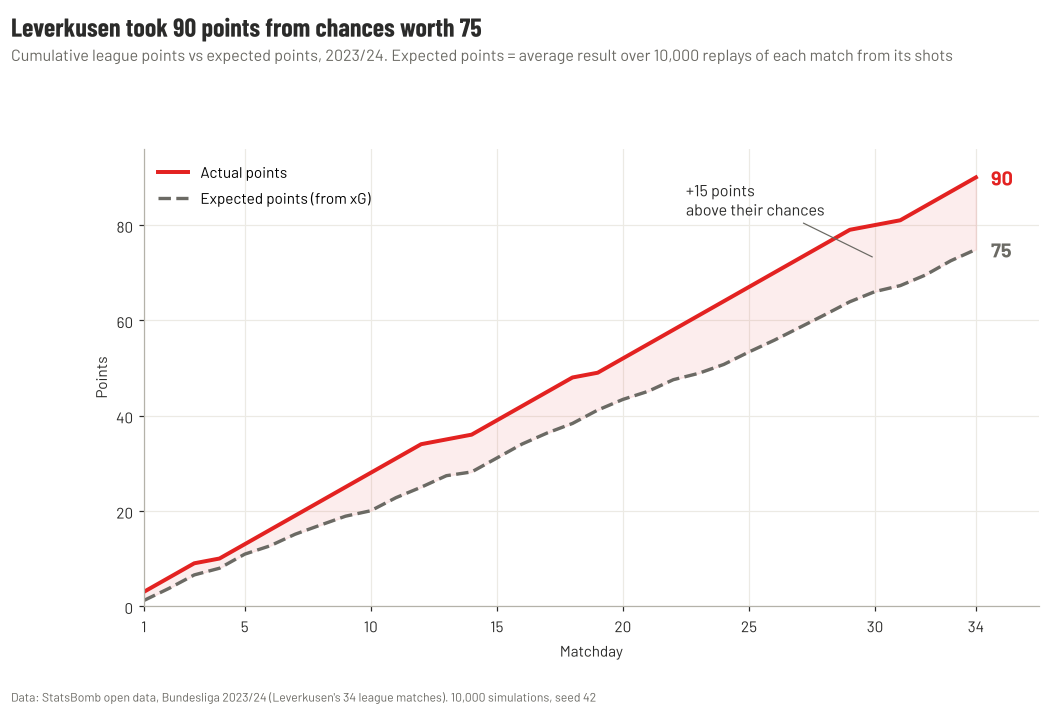

In [4]:
# Figure 10: points vs expected points through the season
fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.plot(R.n, R.pts.cumsum(), color=RED, lw=2.6, label="Actual points")
ax.plot(R.n, R.xpts.cumsum(), color=MUTED, lw=2.2, ls="--", label="Expected points (from xG)")
ax.fill_between(R.n, R.xpts.cumsum(), R.pts.cumsum(), color=RED, alpha=0.08)
end_p, end_x = R.pts.sum(), R.xpts.sum()
ax.text(34.6, end_p, f"{end_p:.0f}", va="center", fontsize=13, color=RED, fontweight="bold")
ax.text(34.6, end_x, f"{end_x:.0f}", va="center", fontsize=13, color=MUTED, fontweight="bold")
ax.annotate(f"+{end_p - end_x:.0f} points\nabove their chances", xy=(30, (R.pts.cumsum().iloc[29] + R.xpts.cumsum().iloc[29]) / 2),
            xytext=(22.5, 82), fontsize=10.5, color=DARK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_xlim(1, 36.5); ax.set_ylim(0, 96); ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 34])
ax.set_xlabel("Matchday"); ax.set_ylabel("Points"); ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
titles(fig, f"Leverkusen took {end_p:.0f} points from chances worth {end_x:.0f}",
       "Cumulative league points vs expected points, 2023/24. Expected points = average result over 10,000 replays of each match from its shots",
       SRC)
fig.savefig(FIGS / "10_points_vs_expected_points.png")

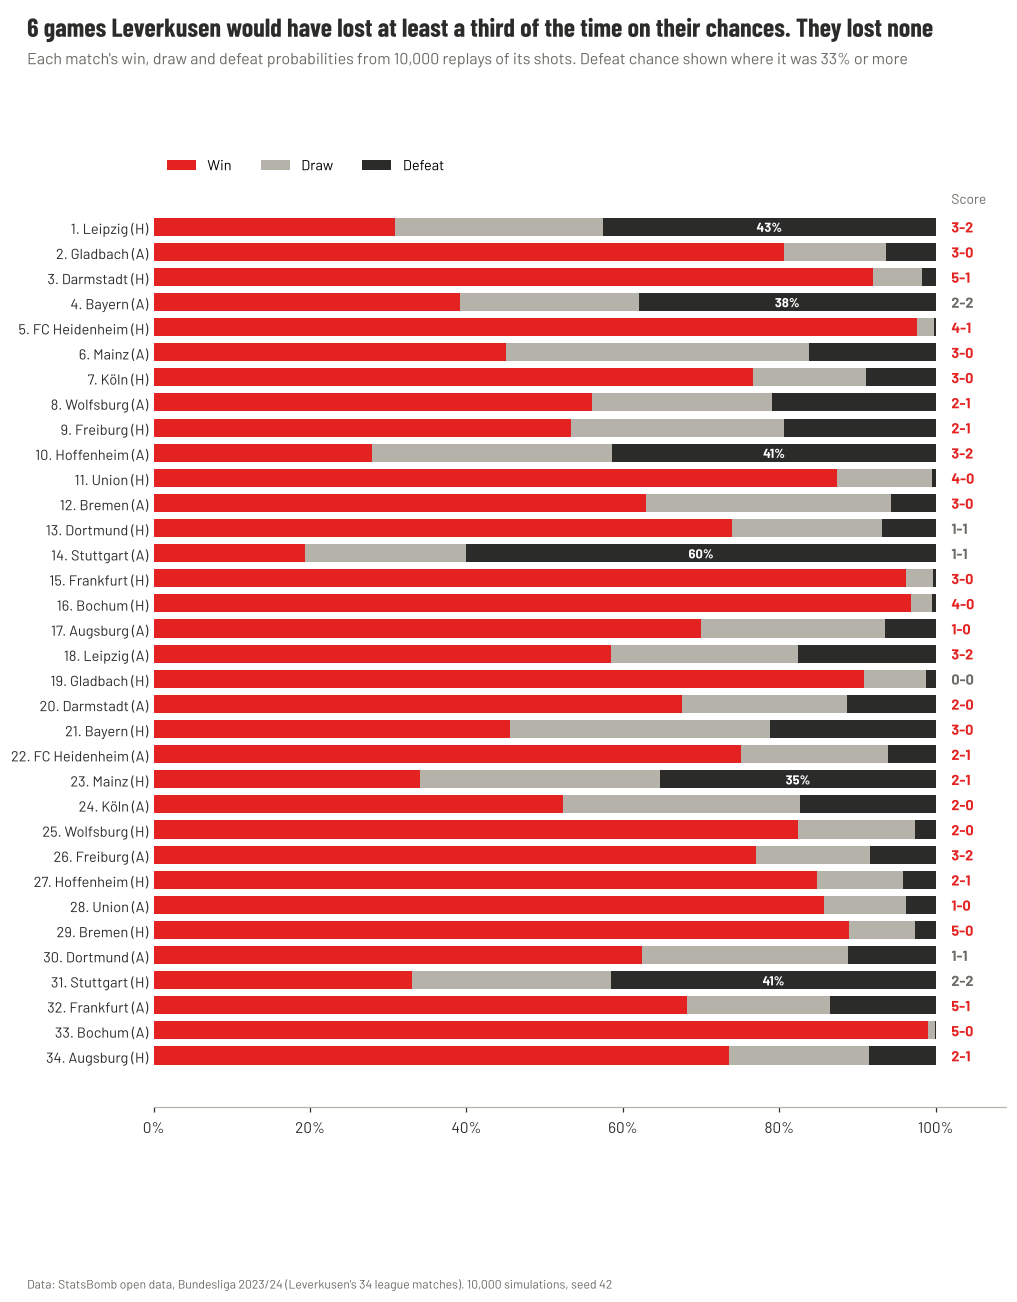

In [5]:
# Figure 11: every match's win / draw / defeat probabilities
fig, ax = plt.subplots(figsize=(10, 11))
y = np.arange(len(R))[::-1]
ax.barh(y, R.p_win, color=RED, height=0.72, label="Win")
ax.barh(y, R.p_draw, left=R.p_win, color=GREY, height=0.72, label="Draw")
ax.barh(y, R.p_loss, left=R.p_win + R.p_draw, color=DARK, height=0.72, label="Defeat")
for yi, r in zip(y, R.itertuples()):
    ax.text(1.02, yi, f"{r.gf}-{r.ga}", va="center", fontsize=9.5, fontweight="bold", color=RED if r.res == "W" else MUTED)
    if r.p_loss >= 0.33:
        ax.text(1 - r.p_loss / 2, yi, f"{r.p_loss:.0%}", va="center", ha="center", fontsize=8.5, color="white", fontweight="bold")
ax.set_yticks(y, [f"{r.n:>2}. {r.label}" for r in R.itertuples()], fontsize=9.5)
ax.set_xlim(0, 1.09); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}" if v <= 1 else "")
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.text(1.02, len(R) - 0.2, "Score", fontsize=9, color=MUTED, va="bottom")
ax.legend(ncol=3, frameon=False, loc="upper left", bbox_to_anchor=(0, 1.035), fontsize=9.5)
n_risk = int((R.p_loss >= 0.33).sum())
titles(fig, f"{n_risk} games Leverkusen would have lost at least a third of the time on their chances. They lost none",
       "Each match's win, draw and defeat probabilities from 10,000 replays of its shots. Defeat chance shown where it was 33% or more",
       SRC, y=0.99)
fig.savefig(FIGS / "11_match_probabilities.png")

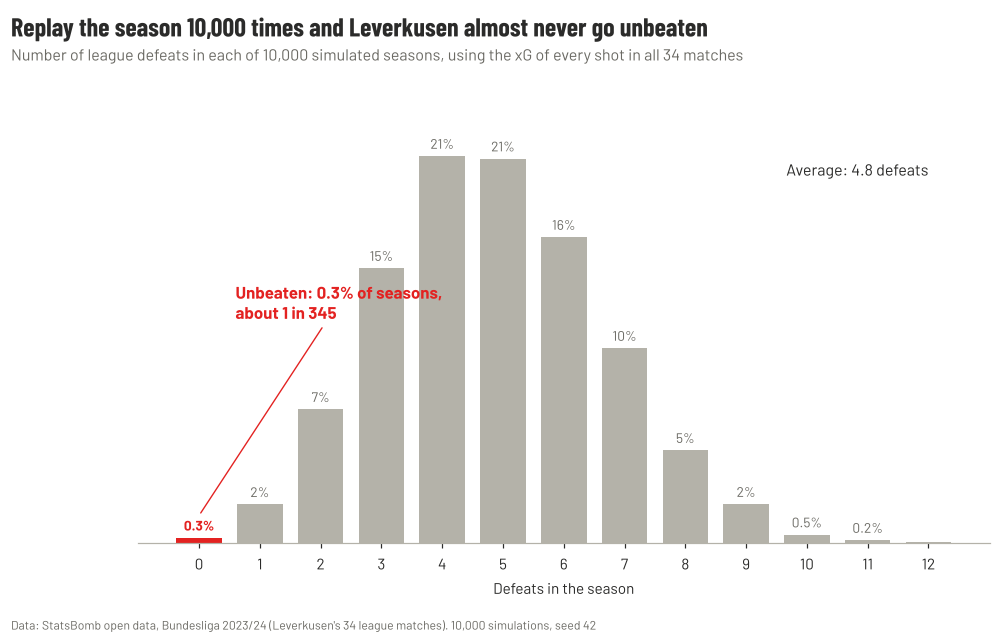

In [6]:
# Figure 12: defeats in 10,000 simulated seasons
cnt = pd.Series(season_losses).value_counts().sort_index()
cnt = cnt.reindex(range(0, cnt.index.max() + 1), fill_value=0) / N
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(cnt.index, cnt.values, color=[RED if i == 0 else GREY for i in cnt.index], width=0.75)
for i, v in cnt.items():
    if v >= 0.001:
        ax.text(i, v + 0.004, f"{v:.1%}" if v < 0.01 else f"{v:.0%}", ha="center", fontsize=9, color=RED if i == 0 else MUTED,
                fontweight="bold" if i == 0 else "normal")
ax.annotate(f"Unbeaten: {cnt[0]:.1%} of seasons,\nabout 1 in {1 / cnt[0]:,.0f}", xy=(0, cnt[0] + 0.012), xytext=(0.6, 0.12),
            fontsize=11, color=RED, fontweight="bold", arrowprops=dict(arrowstyle="-", color=RED, lw=0.9))
ax.set_xticks(cnt.index); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel("Defeats in the season")
ax.text(cnt.index.max(), cnt.max() * 0.95, f"Average: {season_losses.mean():.1f} defeats", ha="right", fontsize=10.5, color=DARK)
titles(fig, "Replay the season 10,000 times and Leverkusen almost never go unbeaten",
       "Number of league defeats in each of 10,000 simulated seasons, using the xG of every shot in all 34 matches",
       SRC)
fig.savefig(FIGS / "12_simulated_defeats.png")